# Spiking Handwritten Digits Classifier using `superneuromat`

Try it on colab: [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1A8skdSiRBrl6bbrIs_BXauZIF-5IhE9R?usp=sharing)

In this section of the tutorial, we'll go through how to create a classifier for handwritten digits using the [SuperNeuroMAT](https://github.com/ORNL/superneuromat) library, a matrix-based Spiking Neural Network (SNN) simulator.


**Documentation** for SuperNeuroMAT is available online:  
[<img src="https://gist.githubusercontent.com/cxmeel/0dbc95191f239b631c3874f4ccf114e2/raw/documentation.svg" alt="Documentation" height="40" />](https://ORNL.github.io/superneuromat/)

Or, if you run the next cell before the runtime starts, you'll get helpful hint popups when you hover over functions!

## Importing SuperNeuroMAT

In [134]:
# !uv pip install superneuromat  # for colab
# !pip install superneuromat scikit-learn matplotlib tqdm  # for those at home

In [135]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import superneuromat as snm

# Print the version of superneuromat to verify installation
print(snm.__version__)

3.5.0


## Understanding the Problem

Vaguely based on the scikit-learn [Recognizing hand-written digits](https://scikit-learn.org/stable/auto_examples/classification/plot_digits_classification.html#sphx-glr-auto-examples-classification-plot-digits-classification-py) tutorial

First, let's load our dataset: [Digits](https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset).
This is a dataset of almost 1,800 images of hand-written digits.

It's important to know what the data you're working with looks like, so please take a moment to examine the shape of the dataset.

The digits dataset contains 8x8 4-bit grayscale images of $1797$ handwritten digits. Each digit is represented as a vector of $64$ values ranging from $[0, 15]$.

Data  shape: (1797, 64)
Input shape: 64
data[0]: [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
data values range between 0 and 16
Image shape: (8, 8)
Label: 0


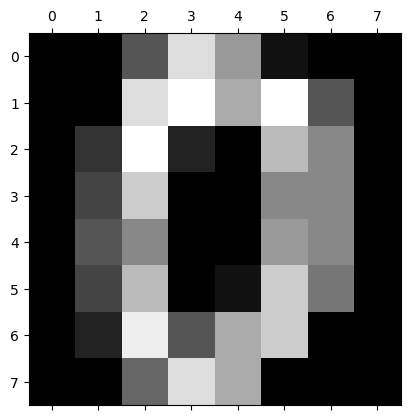

In [136]:
# Load the digits dataset, which contains 1797 8x8 grayscale images of handwritten digits (0-9)
digits = load_digits()
example = digits.data[0]
input_min, input_max = digits.data.min(), digits.data.max()


# Get the number of pixels (inputs) and number of classes (outputs)
input_size = example.size
print(f'Data  shape: {digits.data.shape}')
print(f'Input shape: {input_size}')
print(f'data[0]: {example}')
print(f'data values range between {input_min:g} and {input_max:g}')


# Plot the first image and print its label
plt.matshow(digits.images[0], cmap='grey')
print(f"Image shape: {digits.images[0].shape}")
print(f"Label: {digits.target[0]}")

## Preprocess the Data


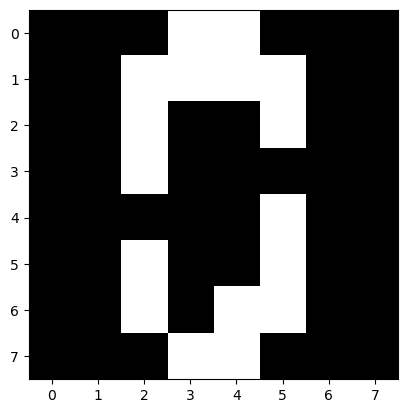

In [137]:
# Metadata 
NUM_PIXELS = digits.data.shape[1]
NUM_CLASSES = len(set(digits.target))


# Hyperparameters for training
NUM_EPOCHS = 10


# Convert images to binary images, i.e., each pixel is either on (1) or off (0)
digits.data = digits.data / digits.data.max()
digits.data = np.round(digits.data)


# Plot the first image
plt.imshow(digits.data[0].reshape(8, 8), cmap='gray')


# Split data into 80% train and 20% test subsets
Xtrain, Xtest, Ytrain, Ytest = train_test_split(digits.data, digits.target, test_size=0.2)

---


# Our Solution

There are many possible approaches to solve this problem. Since this tutorial is all about getting to know SuperNeuroMAT, we're going to build a simple two-layer feedforward network of LIF (leaky-integrate-and-fire) neurons.

We'll send the value of each pixel as spikes to an associated input neuron. Then, we'll train the network using STDP by sending spikes to a target neuron, so that when we want to make an inference, we send in an image and get spikes at the correct output neuron.

## Step 1: Create SNN

Let's build our network now! Let's start by creating the SNN (spiking neural network) object in SuperNeuroMAT.
<a id='network_construction' name='network_construction'></a>

In [138]:
# Create an SNN (spiking neural network) object in SuperNeuroMAT
snn = snm.SNN()


# Print the SNN to see a blank SNN
print(snn)

SNN with 0 neurons and 0 synapses @ 0x15951f3e0
STDP is globally enabled
apos: []
aneg: []
0 synapses have STDP enabled.

Neuron Info (0):
   idx       state      thresh        leak  ref_state  ref_period spikes


Synapse Info (0):
    idx    pre ->   post      weight    delay stdp_enabled


Input Spikes (0) for 0 time steps:
 Time:  Spike-value    Destination


Spike Train:
 t|id 
0 spikes since last reset


## Step 2: Create Neurons

We will now create `NUM_PIXELS` ($64$) input neurons, each with a threshold of $0.0$. Remember that the pixels have binary values, i.e., $0$ or $1$. So, in creating input neurons with a threshold of $0.0$, we allow spikes to those input neurons where the pixel value is $1$ or higher. SuperNeuroMAT implements strictly greater than thresholding.

We will also create `NUM_CLASSES` ($10$) output neurons, each with a threshold of $20.0$. We anticipate the synaptic weights to be in the interval $(0,1)$ and do not want the output neurons to spike because of the SNN during the training. We will explicitly spike the output neurons. This is a supervised training approach.

We will store the input and output neurons in their own separate lists. This will come in handy for adding spikes later.

In [139]:
# Create input neurons 
input_neurons = []
for i in range(NUM_PIXELS):
    neuron = snn.create_neuron(threshold=0.0)
    input_neurons.append(neuron.idx)


# Create output neurons
output_neurons = []
for i in range(NUM_CLASSES):
    neuron = snn.create_neuron(threshold=20.0)
    output_neurons.append(neuron.idx)


# Print the SNN to see the input and output neuron parameters
# SNN should now have 64 input neurons + 10 output neurons = 74 neurons in total
snn.pretty_print(10)

SNN with 74 neurons and 0 synapses @ 0x15951f3e0
STDP is globally enabled
apos: []
aneg: []
0 synapses have STDP enabled.

Neuron Info (74):
   idx       state      thresh        leak  ref_state  ref_period spikes
     0           0           0         inf          0           0 []
     1           0           0         inf          0           0 []
     2           0           0         inf          0           0 []
     3           0           0         inf          0           0 []
     4           0           0         inf          0           0 []
  ...          ...         ...          ...       ...         ... [...]
    69           0          20         inf          0           0 []
    70           0          20         inf          0           0 []
    71           0          20         inf          0           0 []
    72           0          20         inf          0           0 []
    73           0          20         inf          0           0 []

Synapse Info (0):
    i

## Step 3: Create Synapses

We will create synapses from all input neurons to all output neurons, a fully connected layer! We will randomly initialize the weights of these synapses in the interval $(-0.00001,0.00001)$.

In [140]:
# Connect each input neuron to each output neuron with a synapse that is randomly initialized
for input_neuron in input_neurons:
    for output_neuron in output_neurons:
        weight = 0.0 #(2 * np.random.random() - 1) * 0.00001
        snn.create_synapse(input_neuron, output_neuron, weight=weight, stdp_enabled=True)


# Print SNN to see the synapse parameters in addition to the neuron parameters
# There should be 64 * 10 = 640 synapses in total
snn.pretty_print(10)

SNN with 74 neurons and 640 synapses @ 0x15951f3e0
STDP is globally enabled
apos: []
aneg: []
640 synapses have STDP enabled.

Neuron Info (74):
   idx       state      thresh        leak  ref_state  ref_period spikes
     0           0           0         inf          0           0 []
     1           0           0         inf          0           0 []
     2           0           0         inf          0           0 []
     3           0           0         inf          0           0 []
     4           0           0         inf          0           0 []
  ...          ...         ...          ...       ...         ... [...]
    69           0          20         inf          0           0 []
    70           0          20         inf          0           0 []
    71           0          20         inf          0           0 []
    72           0          20         inf          0           0 []
    73           0          20         inf          0           0 []

Synapse Info (640):

## Step 4: Add Spikes

We will now add spikes for all the input and output neurons. 

For each image in the training dataset, we will add a spike to all the input neurons with a value of the corresponding pixel at even time steps $0, 2, 4, \ldots$. 

For each image in the training dataset, we will add a spike for the output neuron corresponding to its label at odd time steps, i.e. $1, 3, 5, \ldots$.

So, for `image[0]`, the pixel neurons (inputs) will spike at time step $0$ and the label neurons (outputs) will spike at time step $1$.

In [141]:
# Add spikes to the input and output neurons
time_step = 0

for t in range(NUM_EPOCHS):
    for i in range(len(Xtrain)):
        for j in range(NUM_PIXELS):
            if Xtrain[i][j] == 1:
                neuron_id = input_neurons[j]
                value = 1.0
                snn.add_spike(time = time_step, neuron_id = neuron_id, value = value)
        
        # Add a huge spike to the correct output neuron to ensure it spikes and causes STDP to update the synaptic weights
        snn.add_spike(time = time_step + 1, neuron_id = output_neurons[Ytrain[i]], value = 100.0)
        time_step += 2


# Print SNN to see the input spikes
snn.pretty_print(10)

SNN with 74 neurons and 640 synapses @ 0x15951f3e0
STDP is globally enabled
apos: []
aneg: []
640 synapses have STDP enabled.

Neuron Info (74):
   idx       state      thresh        leak  ref_state  ref_period spikes
     0           0           0         inf          0           0 []
     1           0           0         inf          0           0 []
     2           0           0         inf          0           0 []
     3           0           0         inf          0           0 []
     4           0           0         inf          0           0 []
  ...          ...         ...          ...       ...         ... [...]
    69           0          20         inf          0           0 []
    70           0          20         inf          0           0 []
    71           0          20         inf          0           0 []
    72           0          20         inf          0           0 []
    73           0          20         inf          0           0 []

Synapse Info (640):

## Step 5: Setup STDP

Now that we have a way to encode a digit to `input_spikes`, let's setup our training loop.

SuperNeuroMAT's built-in training methodology is a type of STDP (Spike Timing Dependent Plasticity).

We use a discrete approach to STDP, defined by a vector for positive and negative weight updates.

`apos` defines the positive weight change that should happen if there is a causal link on a synapse: If the pre-synaptic neuron spikes, and then the post-synaptic neuron spikes on the following time step, then we add `apos[0]` to the weight on that synapse. If the post-synaptic neuron happens to spike two time steps after the pre-synaptic neuron, then we add `apos[1]`, and so on.

Similarly, `aneg` defines a negative weight update for the synapse. If STDP is enabled on that synapse, and we didn't apply `apos`, we instead apply `aneg`.

Here, we will use STDP over 1 time step only.

In [142]:
# Set the STDP parameters globally for all synapses in the SNN
snn.stdp = True
snn.apos = [0.0001]
snn.aneg = [-0.0000001]


# Print the SNN to see the STDP parameters in addition to the neuron and synapse parameters
snn.pretty_print(10)

SNN with 74 neurons and 640 synapses @ 0x15951f3e0
STDP is globally enabled over 1 time steps.
apos: [0.0001]
aneg: [-1e-07]
640 synapses have STDP enabled.

Neuron Info (74):
   idx       state      thresh        leak  ref_state  ref_period spikes
     0           0           0         inf          0           0 []
     1           0           0         inf          0           0 []
     2           0           0         inf          0           0 []
     3           0           0         inf          0           0 []
     4           0           0         inf          0           0 []
  ...          ...         ...          ...       ...         ... [...]
    69           0          20         inf          0           0 []
    70           0          20         inf          0           0 []
    71           0          20         inf          0           0 []
    72           0          20         inf          0           0 []
    73           0          20         inf          0     

## Step 6: Simulate

We will simulate the SNN for $2874$ time steps. There are $1437$ points in the training set (we can verify this with the print statement below), and each point is simulated for $2$ time steps. 

In [143]:
# Verify that Xtrain contains 1437 data points
print(Xtrain.shape)


# Simulate the SNN for Xtrain.shape[0] * NUM_EPOCHS + 100 time steps, which should be enough time for all input and output spikes to occur
snn.simulate(time_steps = Xtrain.shape[0] * NUM_EPOCHS + 100)  


# Print SNN to see the spike train after simulation
snn.pretty_print(20)

(1437, 64)
SNN with 74 neurons and 640 synapses @ 0x15951f3e0
STDP is globally enabled over 1 time steps.
apos: [0.0001]
aneg: [-1e-07]
640 synapses have STDP enabled.

Neuron Info (74):
   idx       state      thresh        leak  ref_state  ref_period spikes
     0           0           0         inf          0           0 [----⋯------]
     1           0           0         inf          0           0 [----⋯------]
     2           0           0         inf          0           0 [----⋯------]
     3           0           0         inf          0           0 [--┴-⋯┴-┴---]
     4           0           0         inf          0           0 [--┴-⋯┴-┴---]
     5           0           0         inf          0           0 [┴-┴-⋯----┴-]
     6           0           0         inf          0           0 [----⋯----┴-]
     7           0           0         inf          0           0 [----⋯------]
     8           0           0         inf          0           0 [----⋯------]
     9           0  

After running all of the `X_train` set through, we can look at the waterfall of spikes from every neuron. Each vertical line represents the spikes from a neuron over time.

In this case, because we created the outputs last, the last ten columns (id 64 through 73) are the outputs.

---
## What did we learn?

Let's visualize the weight matrix.


Weights shape: (74, 74)
Weights:
[[ 0.         0.         0.        ... -0.0014469 -0.0014469 -0.0014469]
 [ 0.         0.         0.        ... -0.0014469 -0.0014469 -0.0014469]
 [ 0.         0.         0.        ...  0.0131677  0.0152698  0.0180726]
 ...
 [ 0.         0.         0.        ...  0.         0.         0.       ]
 [ 0.         0.         0.        ...  0.         0.         0.       ]
 [ 0.         0.         0.        ...  0.         0.         0.       ]]


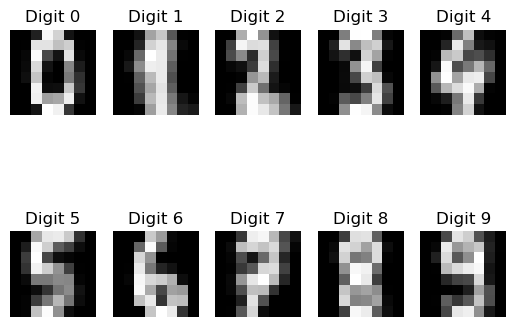

In [ ]:
rows, cols = 2, 5
_, axes = plt.subplots(nrows=rows, ncols=cols)
weights = snn.weight_mat()[:NUM_PIXELS, NUM_PIXELS:]

digit = 0

for row in axes:
    for col in row:
        col.set_axis_off()
        col.set_title(f"Digit {digit}")
        col.imshow(weights.reshape(8, 8), cmap='gray')
        digit += 1

print(f"Weights shape: {weights.shape}")
print("Weights:")
print(weights)

---
## 